# Deposit NII & margin — self-contained Shapley analysis

**Purpose:** Reproduce a nine-quarter (27-month) CCAR deposit attribution using **simulated** dollar data. No external input files required.

The notebook runs two reporting modes:
1. **CCAR Baseline vs Business Outlook**, within the current cycle.
2. **Cycle-over-cycle** change in **(Severe − Baseline)** from the prior to current cycle.

Each mode has a **NII dollar waterfall** and a **margin basis-point waterfall**, followed by concise scenario context and reconciliation tests.

**Important interpretation:** With aggregate FTP dollars, the FTP yield is blended. The *mix* effect in the four-factor identity captures IB interest-expense exposure, not a fully identified FTP product-mix effect. The attribution is mathematically exact under this convention, but is not a causal product repricing breakdown.

## 1. Setup and simulated input

Edit `COLUMN_MAP` if you later import your own CSV. Dollar values use **$ millions** throughout. The annualization uses `tau=1/12` per month, so 27 months = 2.25 years. Projected periods exclude month 0.

In [1]:
import itertools
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
OUTPUT = Path('deposit_notebook_results')
OUTPUT.mkdir(exist_ok=True)

COLUMN_MAP = {
    'period': 'month', 'scenario': 'scenario', 'cycle': 'cycle',
    'ftp': 'ftp_dollars', 'expense': 'interest_expense_dollars',
    'total': 'total_avg_balance', 'dda': 'dda_avg_balance',
    'ib': 'ib_avg_balance', 'fed_funds': 'fed_funds_rate',
}

# Use any two scenarios in each reporting mode.
CURRENT_CYCLE = '2026'
PRIOR_CYCLE = '2025'
BASE = 'Baseline'
STRESS = 'Severe'
OUTLOOK = 'Outlook'


In [2]:
def make_sample():
    rng = np.random.default_rng(20261109)
    rows = []
    for cycle, first_month, book_scale in [('2025','2026-01-01',1.0),('2026','2027-01-01',1.075)]:
        months = pd.date_range(first_month, periods=27, freq='MS')
        for scenario in ['Baseline','Severe','Outlook']:
            for t, month in enumerate(months):
                # Purposefully different volume, mix, FTP and deposit-pricing paths.
                base_balance = book_scale * (108000 + 260*t + 550*np.sin(t/3))
                scenario_multiplier = {'Baseline':1.0,'Severe':0.96-0.0012*t,'Outlook':1.025+0.0005*t}[scenario]
                total = base_balance * scenario_multiplier
                dda_share = {'Baseline':0.385,'Severe':0.355,'Outlook':0.395}[scenario] - 0.0006*t
                dda = total*dda_share; ib = total-dda
                # Rate paths are inputs to the simulator only, not required by the attribution.
                ff = {'Baseline':4.3-0.045*t,'Severe':4.3-0.095*t,'Outlook':4.2-0.040*t}[scenario]
                ff += (0.06 if cycle=='2026' else 0)
                blended_ftp = max(0.004, ff/100 - 0.0025 + (0.0006 if scenario=='Outlook' else 0))
                ib_paid = max(0.002, 0.013 + 0.43*(ff/100-0.03) + (0.0005 if scenario=='Outlook' else 0))
                ftp = total*blended_ftp/12
                expense = ib*ib_paid/12
                rows.append([month.strftime('%Y-%m-%d'),scenario,cycle,ftp,expense,total,dda,ib,ff])
    return pd.DataFrame(rows,columns=['month','scenario','cycle','ftp_dollars',
                     'interest_expense_dollars','total_avg_balance','dda_avg_balance',
                     'ib_avg_balance','fed_funds_rate'])

simulated = make_sample()
csv_path = OUTPUT/'sample_deposits_two_cycles.csv'
simulated.to_csv(csv_path,index=False)
print(f'Simulated {len(simulated)} rows; saved to {csv_path}')
display(simulated.head(6))


Simulated 162 rows; saved to deposit_notebook_results/sample_deposits_two_cycles.csv


,month,scenario,cycle,ftp_dollars,interest_expense_dollars,total_avg_balance,dda_avg_balance,ib_avg_balance,fed_funds_rate
0,2026-01-01,Baseline,2025,364.500,102.896,"108,000.000","41,580.000","66,420.000",4.300
1,2026-02-01,Baseline,2025,361.918,102.339,"108,439.957","41,684.320","66,755.638",4.255
2,2026-03-01,Baseline,2025,359.238,101.754,"108,860.103","41,780.508","67,079.596",4.210
3,2026-04-01,Baseline,2025,356.405,101.125,"109,242.809","41,861.844","67,380.965",4.165
4,2026-05-01,Baseline,2025,353.378,100.440,"109,574.566","41,923.229","67,651.337",4.120
5,2026-06-01,Baseline,2025,350.139,99.693,"109,847.474","41,961.735","67,885.739",4.075


## 2. Calculation engine

At each month, define `B = DDA + IB`, `w = DDA/B`, `f = FTP dollars/(B·τ)`, and `r = interest-expense dollars/(IB·τ)`.

\[
NII_t=B_t	au_t\,[f_t-(1-w_t)r_t], \qquad
M_{1:27}=rac{\sum_t NII_t}{\sum_t B_t	au_t}.
\]

Shapley averages the incremental change in each factor over all **24 permutations** of Balance, Mix, blended FTP yield and IB paid rate. The month-by-month NII contributions sum to the full-horizon NII contributions; margin contributions are calculated on the **full-horizon ratio**, not summed from individual monthly margins.

In [3]:
import itertools
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

COLUMN_MAP = {
    'period': 'month', 'scenario': 'scenario', 'cycle': 'cycle',
    'ftp': 'ftp_dollars', 'expense': 'interest_expense_dollars',
    'total': 'total_avg_balance', 'dda': 'dda_avg_balance',
    'ib': 'ib_avg_balance', 'fed_funds': 'fed_funds_rate',
}
FACTORS = ('Balance', 'Mix', 'FTP yield', 'IB paid rate')
COLORS = ['#3274A1','#9064A1','#C48736','#32866C']


def load_data(path, day_count='fixed', mapping=COLUMN_MAP):
    raw = pd.read_csv(path)
    mandatory = ['period','scenario','ftp','expense','total','dda','ib']
    missing = [mapping[k] for k in mandatory if mapping[k] not in raw]
    if missing: raise ValueError(f'Missing required columns: {missing}')
    optional = [k for k in ('cycle','fed_funds') if mapping[k] in raw]
    x = raw[[mapping[k] for k in mandatory+optional]].rename(
        columns={mapping[k]:k for k in mandatory+optional})
    x['period'] = pd.to_datetime(x['period'], errors='raise')
    if x.period.isna().any(): raise ValueError('Missing periods')
    if not x.period.dt.is_month_start.all(): raise ValueError('Monthly dates must be first day of month')
    for k in ('ftp','expense','total','dda','ib'):
        x[k]=pd.to_numeric(x[k],errors='raise')
    if x[['ftp','expense','total','dda','ib']].isna().any().any():
        raise ValueError('Missing numeric values')
    if (x[['total','ib']]<=0).any().any() or (x.dda<0).any():
        raise ValueError('Total/IB must be positive; DDA nonnegative')
    if (x.expense<0).any(): raise ValueError('Interest expense must be a positive dollar cost')
    if ((x.total-x.dda-x.ib).abs()>np.maximum(1e-6, x.total.abs()*1e-6)).any():
        raise ValueError('Total average balance must equal DDA + IB')
    if 'cycle' not in x: x['cycle']='single'
    x['cycle']=x['cycle'].astype(str)
    key=['cycle','scenario','period']
    if x.duplicated(key).any(): raise ValueError('Duplicate cycle/scenario/month rows')
    x=x.sort_values(key).reset_index(drop=True)
    if day_count=='fixed':
        x['tau']=1/12  # 27 periods -> precisely 2.25 years, consistent with report shortcut
    elif day_count=='actual':
        x['tau']=x.period.dt.days_in_month/365
    else: raise ValueError('day_count must be fixed or actual')
    x['mix']=x.dda/x.total
    x['ftp_yield']=x.ftp/(x.total*x.tau)
    x['paid_yield']=x.expense/(x.ib*x.tau)
    x['nii']=x.ftp-x.expense
    return x


def factor_arrays(d):
    return {'Balance':d.total.to_numpy(float), 'Mix':d.mix.to_numpy(float),
            'FTP yield':d.ftp_yield.to_numpy(float),
            'IB paid rate':d.paid_yield.to_numpy(float)}


def evaluate(state,tau):
    b=state['Balance']; w=state['Mix']; f=state['FTP yield']; r=state['IB paid rate']
    exposure=b*tau
    monthly=exposure*(f-(1-w)*r)
    return monthly, float(monthly.sum()/exposure.sum())


def shapley(A,B,tau):
    n={k:np.zeros(len(tau)) for k in FACTORS}
    m={k:0.0 for k in FACTORS}
    for order in itertools.permutations(FACTORS):
        state=dict(A)
        prev_nii,prev_margin=evaluate(state,tau)
        for k in order:
            state[k]=B[k]
            next_nii,next_margin=evaluate(state,tau)
            n[k]+=(next_nii-prev_nii)/24
            m[k]+=(next_margin-prev_margin)*10000/24
            prev_nii,prev_margin=next_nii,next_margin
    return n,m


def selected(x,cycle,scenario):
    d=x[(x.cycle==str(cycle))&(x.scenario==scenario)].sort_values('period').reset_index(drop=True)
    if d.empty: raise ValueError(f'No data for cycle={cycle}, scenario={scenario}')
    return d


def compare(a,b,allow_calendar_shift=False):
    if len(a)!=len(b): raise ValueError('Both paths must have same number of monthly observations')
    if not allow_calendar_shift and not a.period.equals(b.period):
        raise ValueError('Comparison requires matching calendar months')
    if not np.allclose(a.tau.to_numpy(),b.tau.to_numpy()):
        raise ValueError('Accrual fractions differ; use fixed 1/12 for relative-horizon comparison')
    if len(a)!=27: print('NOTE: comparison includes',len(a),'months (not 27)')
    tau=a.tau.to_numpy()
    A=factor_arrays(a);B=factor_arrays(b)
    na,ma=evaluate(A,tau); nb,mb=evaluate(B,tau)
    contributions_n,contributions_m=shapley(A,B,tau)
    result={
        'nii_a':float(na.sum()),'nii_b':float(nb.sum()),
        'margin_a':ma*10000,'margin_b':mb*10000,
        'n':{k:float(contributions_n[k].sum()) for k in FACTORS},
        'm':contributions_m,
        'monthly':pd.DataFrame({'month_index':np.arange(1,len(a)+1),'nii_a':na,'nii_b':nb,
                                **{f'{k}_nii':contributions_n[k] for k in FACTORS}}),
        'exposure_a':float((a.total*a.tau).sum()),
        'exposure_b':float((b.total*b.tau).sum()),
    }
    assert np.isclose(sum(result['n'].values()),result['nii_b']-result['nii_a'],atol=1e-7,rtol=0)
    assert np.isclose(sum(result['m'].values()),result['margin_b']-result['margin_a'],atol=1e-8,rtol=0)
    assert np.allclose(result['monthly'][[f'{k}_nii' for k in FACTORS]].sum(axis=1),nb-na,atol=1e-7)
    return result


def plot_waterfall(path,title,start,contributions,unit):
    keys=list(contributions)
    values=np.array([contributions[k] for k in keys])
    fig,ax=plt.subplots(figsize=(10.5,4.7))
    ax.bar(0,start,color='#30485e',width=.68)
    current=start
    for i,(k,v) in enumerate(zip(keys,values),start=1):
        ax.bar(i,abs(v),bottom=min(current,current+v),color=COLORS[i-1],width=.68)
        ax.text(i,current+v/2,f'{v:+,.1f}',ha='center',va='center',fontsize=9,fontweight='bold')
        current+=v
    ax.bar(len(keys)+1,current,color='#30485e',width=.68)
    ax.set_xticks(range(len(keys)+2),['Reference',*keys,'Comparison'])
    ax.set_ylabel(unit)
    ax.set_title(title,loc='left',fontweight='bold',fontsize=14)
    ax.axhline(0,lw=.7,color='gray');ax.grid(axis='y',alpha=.12)
    ax.spines[['top','right']].set_visible(False)
    fig.tight_layout();fig.savefig(path,dpi=170,bbox_inches='tight');plt.close(fig)


def save_result(out,prefix,result,description):
    tab=pd.DataFrame({'factor':FACTORS,'nii_dollars':[result['n'][k] for k in FACTORS],
                      'margin_bps':[result['m'][k] for k in FACTORS]})
    tab.to_csv(out/f'{prefix}_attribution.csv',index=False)
    result['monthly'].to_csv(out/f'{prefix}_monthly.csv',index=False)
    plot_waterfall(out/f'{prefix}_nii.png',description+' — NII',result['nii_a'],result['n'],'NII ($ input units)')
    plot_waterfall(out/f'{prefix}_margin.png',description+' — margin',result['margin_a'],result['m'],'Annualized bps')
    return tab




## 3. Load / validate input and run Scenario A vs B

The same `load_data` routine validates a real CSV. Set `csv_path = Path('your_file.csv')` to switch datasets, and modify `COLUMN_MAP` above as needed.

,Driver,NII change ($MM),Margin change (bps)
0,Balance,211.381,-0.095
1,Mix,45.142,1.648
2,FTP yield,70.625,2.578
3,IB paid rate,-59.937,-2.188


NII: reference, comparison, difference = 6751.775 7018.986 267.211
Margin change (bps) = 1.943


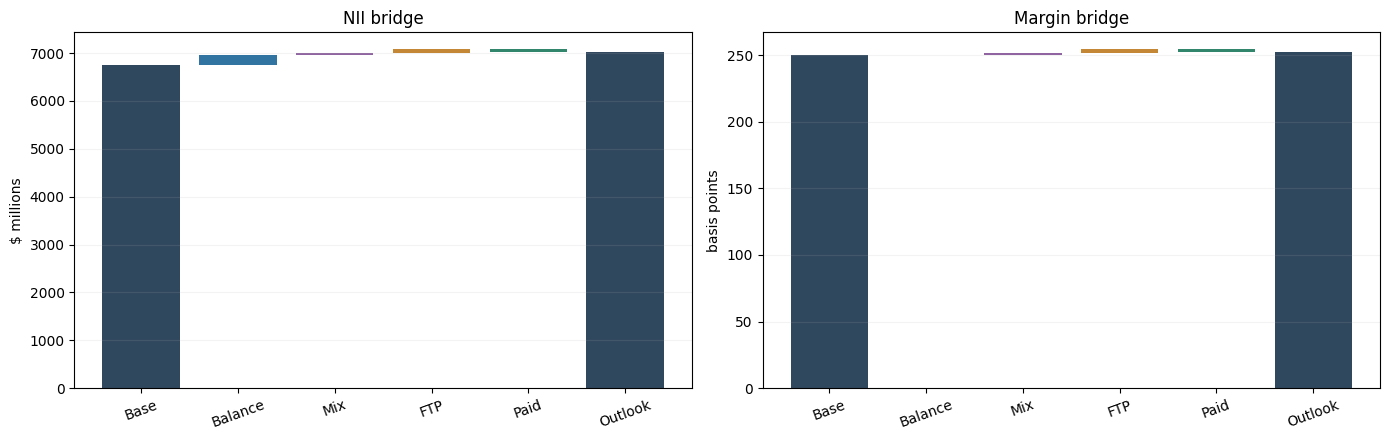

In [4]:
data = load_data(csv_path, day_count='fixed', mapping=COLUMN_MAP)
assert len(data)==3*2*27

# Analysis 1: current CCAR baseline vs business Outlook.
a = selected(data, CURRENT_CYCLE, BASE)
b = selected(data, CURRENT_CYCLE, OUTLOOK)
pair = compare(a,b)

pair_table = pd.DataFrame({
    'Driver':list(FACTORS),
    'NII change ($MM)':[pair['n'][f] for f in FACTORS],
    'Margin change (bps)':[pair['m'][f] for f in FACTORS],
})
display(pair_table)
print('NII: reference, comparison, difference =', round(pair['nii_a'],3), round(pair['nii_b'],3), round(pair['nii_b']-pair['nii_a'],3))
print('Margin change (bps) =', round(pair['margin_b']-pair['margin_a'],3))
plot_waterfall(OUTPUT/'01_base_vs_outlook_nii.png', 'CCAR Baseline vs Business Outlook — NII', pair['nii_a'],pair['n'],'$ millions')
plot_waterfall(OUTPUT/'02_base_vs_outlook_margin.png', 'CCAR Baseline vs Business Outlook — margin', pair['margin_a'],pair['m'],'basis points')
fig,axes=plt.subplots(1,2,figsize=(14,4.5))
for ax, (name,start,contrib,ylabel) in zip(axes,[('NII',pair['nii_a'],pair['n'],'$ millions'),('Margin',pair['margin_a'],pair['m'],'basis points')]):
    k=list(contrib); cur=start
    ax.bar(0,start,color='#30485e')
    for i,f in enumerate(k,1):
        v=contrib[f];ax.bar(i,abs(v),bottom=min(cur,cur+v),color=COLORS[i-1]);cur+=v
    ax.bar(5,cur,color='#30485e');ax.set_xticks(range(6),['Base','Balance','Mix','FTP','Paid','Outlook'],rotation=20)
    ax.set_title(name+' bridge');ax.set_ylabel(ylabel);ax.grid(axis='y',alpha=.15)
plt.tight_layout();plt.show()


## 4. Cycle-over-cycle: change in (Severe − Baseline)

Compute a four-factor stress-versus-baseline bridge within **each cycle**, then subtract prior contributions from current contributions. Both individual bridges and the difference bridge reconcile. This is a descriptive difference-in-differences, not causal identification.

,Driver,Prior stress NII ($MM),Current stress NII ($MM),Change in NII stress effect ($MM),Change in margin stress effect (bps)
0,Balance,-298.115,-327.019,-28.904,0.000
1,Mix,-107.254,-117.327,-10.073,-0.077
2,FTP yield,"-1,597.775","-1,717.608",-119.833,0.000
3,IB paid rate,440.042,473.045,33.003,0.000


Prior / current stress NII: -1563.1 -1688.91
Cycle change in NII stress impact: -125.81
Cycle change in margin stress impact (bps): -0.08


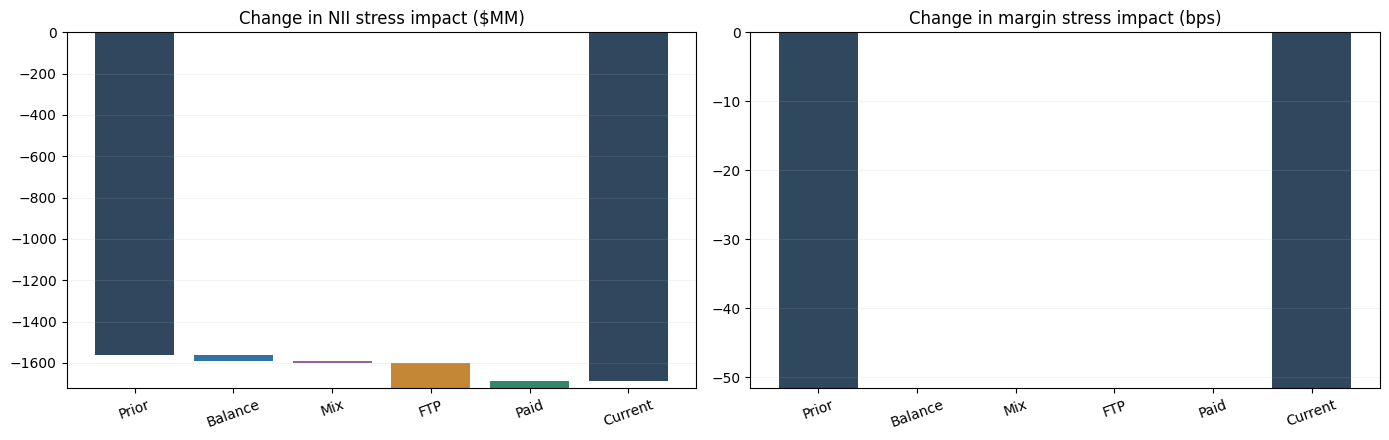

In [5]:
prior = compare(selected(data,PRIOR_CYCLE,BASE), selected(data,PRIOR_CYCLE,STRESS))
current = compare(selected(data,CURRENT_CYCLE,BASE), selected(data,CURRENT_CYCLE,STRESS))

cycle_nii = {f: current['n'][f]-prior['n'][f] for f in FACTORS}
cycle_margin = {f: current['m'][f]-prior['m'][f] for f in FACTORS}
prior_stress_nii = prior['nii_b']-prior['nii_a']
current_stress_nii = current['nii_b']-current['nii_a']
prior_stress_margin = prior['margin_b']-prior['margin_a']
current_stress_margin = current['margin_b']-current['margin_a']

cycle_table = pd.DataFrame({
    'Driver':list(FACTORS),
    'Prior stress NII ($MM)':[prior['n'][f] for f in FACTORS],
    'Current stress NII ($MM)':[current['n'][f] for f in FACTORS],
    'Change in NII stress effect ($MM)':[cycle_nii[f] for f in FACTORS],
    'Change in margin stress effect (bps)':[cycle_margin[f] for f in FACTORS]
})
display(cycle_table)
print('Prior / current stress NII:',round(prior_stress_nii,2),round(current_stress_nii,2))
print('Cycle change in NII stress impact:',round(current_stress_nii-prior_stress_nii,2))
print('Cycle change in margin stress impact (bps):',round(current_stress_margin-prior_stress_margin,2))

plot_waterfall(OUTPUT/'03_cycle_change_nii.png','Current − prior: stress NII impact',prior_stress_nii,cycle_nii,'$ millions')
plot_waterfall(OUTPUT/'04_cycle_change_margin.png','Current − prior: stress margin impact',prior_stress_margin,cycle_margin,'basis points')
fig,axes=plt.subplots(1,2,figsize=(14,4.5))
for ax,(start,contrib,name) in zip(axes,[
    (prior_stress_nii,cycle_nii,'Change in NII stress impact ($MM)'),
    (prior_stress_margin,cycle_margin,'Change in margin stress impact (bps)')]):
    cur=start;ax.bar(0,cur,color='#30485e')
    for i,f in enumerate(FACTORS,1):
        v=contrib[f];ax.bar(i,abs(v),bottom=min(cur,cur+v),color=COLORS[i-1]);cur+=v
    ax.bar(5,cur,color='#30485e');ax.set_xticks(range(6),['Prior','Balance','Mix','FTP','Paid','Current'],rotation=20)
    ax.set_title(name);ax.grid(axis='y',alpha=.15)
plt.tight_layout();plt.show()


## 5. Compare normalized stress impacts and balance / mix context

`Normalized stress NII (bps) = 10,000 × (Stress NII − Baseline NII) / baseline deposit exposure`. This is **not** the stress-minus-base margin difference when balances differ between stress and base.

In [6]:
def summary(d):
    exposure=(d.total*d.tau).sum()
    return {'Mean balance ($MM)':np.average(d.total,weights=d.tau),
            'DDA share (%)':100*(d.dda*d.tau).sum()/exposure,
            'FTP yield (%)':100*d.ftp.sum()/exposure,
            'IB paid rate (%)':100*d.expense.sum()/(d.ib*d.tau).sum(),
            'NII ($MM)':d.nii.sum(),
            'Margin (bps)':10000*d.nii.sum()/exposure}
context = pd.DataFrame({
    'CCAR Base':summary(a), 'Business Outlook':summary(b),
    'Prior Stress':summary(selected(data,PRIOR_CYCLE,STRESS)),
    'Current Stress':summary(selected(data,CURRENT_CYCLE,STRESS)),
}).T
display(context)
normalized=pd.DataFrame({
    'Cycle':['Prior','Current'],
    'Stress impact ($MM)':[prior_stress_nii,current_stress_nii],
    'Normalized impact (bps)':[10000*prior_stress_nii/prior['exposure_a'],10000*current_stress_nii/current['exposure_a']],
    'Margin impact (bps)':[prior_stress_margin,current_stress_margin]
})
display(normalized)
pair_table.to_csv(OUTPUT/'pair_shapley.csv',index=False)
cycle_table.to_csv(OUTPUT/'cycle_shapley.csv',index=False)
context.to_csv(OUTPUT/'scenario_context.csv')
normalized.to_csv(OUTPUT/'normalized_stress.csv',index=False)


,Mean balance ($MM),DDA share (%),FTP yield (%),IB paid rate (%),NII ($MM),Margin (bps)
CCAR Base,"119,853.374",37.712,3.519,1.629,"6,751.775",250.372
Business Outlook,"123,637.235",38.710,3.543,1.664,"7,018.986",252.315
Prior Stress,"105,273.651",34.716,2.809,1.323,"4,607.419",194.516
Current Stress,"113,169.175",34.716,2.869,1.349,"5,062.866",198.832


,Cycle,Stress impact ($MM),Normalized impact (bps),Margin impact (bps)
0,Prior,"-1,563.102",-62.311,-51.463
1,Current,"-1,688.909",-62.629,-51.540


## 6. Monthly timing — one optional diagnostic

These data explain **when** differences accumulated. They are not additional factors in the nine-quarter waterfall.

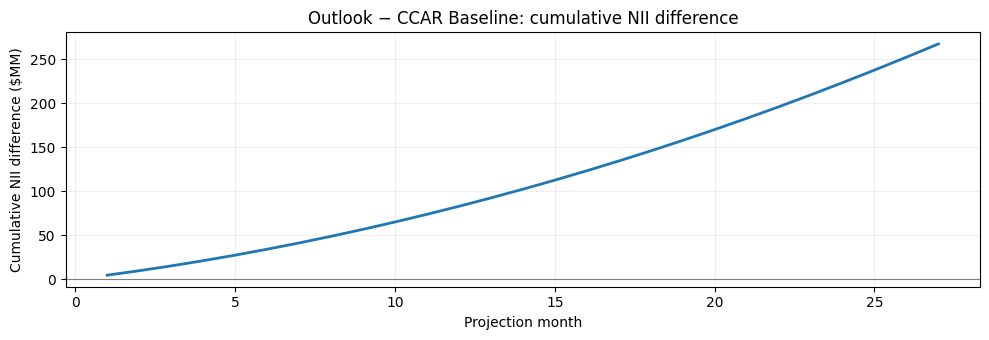

In [7]:
monthly = pair['monthly'].copy()
monthly['cumulative_difference']=(monthly['nii_b']-monthly['nii_a']).cumsum()
monthly['difference']=monthly['nii_b']-monthly['nii_a']
fig,ax=plt.subplots(figsize=(10,3.5))
ax.plot(monthly.month_index,monthly.cumulative_difference,lw=2)
ax.axhline(0,color='gray',lw=.8)
ax.set(xlabel='Projection month',ylabel='Cumulative NII difference ($MM)',title='Outlook − CCAR Baseline: cumulative NII difference')
ax.grid(alpha=.2);plt.tight_layout();plt.savefig(OUTPUT/'05_monthly_cumulative_difference.png',dpi=160);plt.show()
monthly.to_csv(OUTPUT/'monthly_pair_attribution.csv',index=False)


## 7. Automated reconciliation and robustness tests

Tests verify dollar NII identity, monthly and full-horizon Shapley additivity, margin additivity, cycle-over-cycle difference, and invariance of margin under **uniform proportional scaling** of all balances and dollar FTP/interest amounts.

In [8]:
for d in (a,b,selected(data,PRIOR_CYCLE,BASE),selected(data,PRIOR_CYCLE,STRESS)):
    assert np.allclose(d.nii, d.ftp-d.expense)
    assert np.allclose(d.total,d.dda+d.ib)

assert np.isclose(sum(pair['n'].values()),pair['nii_b']-pair['nii_a'],atol=1e-7)
assert np.isclose(sum(pair['m'].values()),pair['margin_b']-pair['margin_a'],atol=1e-8)
assert np.isclose(sum(cycle_nii.values()),current_stress_nii-prior_stress_nii,atol=1e-7)
assert np.isclose(sum(cycle_margin.values()),current_stress_margin-prior_stress_margin,atol=1e-8)

# Uniform growth in book size and matching dollar FTP and expense has no margin effect.
scaled=b.copy()
for field in ('total','dda','ib','ftp','expense','nii'):
    scaled[field] *= 1.25
scaled['mix']=scaled.dda/scaled.total
scaled['ftp_yield']=scaled.ftp/(scaled.total*scaled.tau)
scaled['paid_yield']=scaled.expense/(scaled.ib*scaled.tau)
assert np.isclose(summary(b)['Margin (bps)'],summary(scaled)['Margin (bps)'],atol=1e-8)
assert np.isclose(summary(scaled)['NII ($MM)']/summary(b)['NII ($MM)'],1.25)

# Demonstrate exactly 24 orderings.
orders = list(itertools.permutations(FACTORS))
assert len(orders)==24
print('PASS: 24 Shapley orderings and all reconciliation / scaling checks.')
print('Saved tables, simulated CSV and charts in:',OUTPUT.resolve())


PASS: 24 Shapley orderings and all reconciliation / scaling checks.
Saved tables, simulated CSV and charts in: /mnt/data/deposit_notebook_results


### Interpretation and limitations

- **NII bridge ($):** Balance, DDA/IB mix, blended FTP yield, IB paid rate.
- **Nine-quarter margin bridge (bps):** The 'Balance' factor reflects changes in **relative monthly exposure weights**, not proportional book growth. Uniform scaling contributes zero to margin.
- **Cycle bridge:** Change in Shapley contributions to stress-minus-base between cycles; references are re-established within each cycle.
- **Not separately identified:** FTP-specific DDA-versus-IB mix effects. With aggregate FTP, blended FTP yield incorporates both rate and composition changes. Avoid interpreting the four labels as pure causal effects.
- **Actual P&R data:** Check that period balances are truly average balances, dollar FTP/interest are monthly flows, scenarios have aligned dates within cycle, and dollar amounts use consistent units.
